# Comparing Structural and Reduced-Form Credit Risk Models

## Merton (1974) · VK/KMV (Crosbie & Bohn, 2003) · Hull-White (2000) — CDS Bootstrap

**v5 — CDS-Bootstrapped Hull-White**: the Hull-White hazard rate is now obtained directly from observed 5Y CDS par spreads via the Hull & White (2000) reduced-form pricing identity, rather than from a logistic-regression proxy on accounting features. Two estimators are reported:

1. **Credit-triangle approximation**: $\lambda \approx s/(1-R)$ — closed-form benchmark.
2. **PV equation solver**: a flat hazard $\lambda$ is found numerically by setting the protection-leg PV equal to the premium-leg PV (with quarterly payments and accrual-on-default), discounted at the risk-free rate.

Equity volatility $\sigma_E$ is taken directly from `panel_data.csv` (option-implied with historical fallback, prepared upstream).

**Research questions**:

1. *Discrimination*: which structural model — Merton or VK — better separates distressed firms from healthy firms on a labelled panel?
2. *Calibration*: do the model-implied hazard rates (Merton, VK, Hull-White) align with the market-implied hazard rates derived from CDS spreads?

| Model | Paradigm | Main Output | Key Reference |
|-------|----------|-------------|---------------|
| Merton | Structural | DD, PD, implied $\lambda$ | Merton (1974) |
| VK/KMV | Structural | DD, PD, implied $\lambda$ | Crosbie & Bohn (2003) |
| Hull-White | Reduced-form | $\lambda$ bootstrapped from CDS | Hull & White (2000) |

---

**Scope note on the two evaluations.** The full 163-firm panel contains 21 distressed firms; none of them have liquid 5Y CDS quotes, so the CDS panel is a 84-firm investment-grade subset with zero distress labels. As a consequence, ROC-AUC and CAP-AR can only be computed for the structural models on the labelled panel (Section 6), while the CDS calibration check (Section 7) compares all three models on the IG subset. This is a property of the CDS market, not a modelling choice.


---

# 1. Data Acquisition & Panel Construction

The panel is loaded directly from `panel_data.csv` (pre-built upstream from Yahoo Finance + WRDS OptionMetrics + FRED). No live API calls are made in this notebook.

**Columns used**:
- Identifiers: `ticker`, `year`, `date`
- Equity / debt: `market_cap`, `equity_vol`, `total_debt`, `short_term_debt`, `long_term_debt`, `default_point`
- Rates: `risk_free_rate`
- Labels: `default_label`
- HW features (kept for reference): `leverage_ratio`, `log_market_cap`

## 1.1 Default Label Definition

Default labels are assigned at the **firm level** (static across years) using a broad credit-distress definition rather than strict legal bankruptcy, since formal Chapter 11 filings during 2021-2025 are rare among U.S. listed firms (Shumway, 2001):

| Category | Criteria | Example firms |
|----------|----------|---------------|
| Formal bankruptcy | Court-ordered Chapter 11 | HTZ |
| Going-concern warning | SEC/auditor going-concern opinion | PLUG, FCEL |
| Severe financial distress | Persistent losses, unsustainable cash burn, negative equity, or extreme leverage | LCID, RIVN, BYND, AMC, ... |

> **Limitation**: HTZ is the only firm with an actual default event in the sample period. The remaining 20 are "distress-like" cases. Models may therefore be learning *distress features* rather than strict default probability.


In [6]:
# Cell 2 — Data Load (Section 2 下的唯一 code cell)
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# 让 notebook 能在 notebooks/ 子目录或项目根目录运行
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")

import config

# 自动找数据文件
def _find(filename, candidates=("data", "output", ".", "../data")):
    for d in candidates:
        p = os.path.join(d, filename)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"{filename} not found in {candidates}")

panel = pd.read_csv(_find("panel_data.csv"))

OUT_DIR = "output"
os.makedirs(OUT_DIR, exist_ok=True)

print(f"Panel shape:       {panel.shape}")
print(f"Default firms:     {panel[panel['default_label']==1]['ticker'].nunique()}")
print(f"Non-default firms: {panel[panel['default_label']==0]['ticker'].nunique()}")
print(f"Years covered:     {sorted(panel['year'].unique())}")
panel.head(10)

Panel shape:       (659, 15)
Default firms:     21
Non-default firms: 151
Years covered:     [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,ticker,year,date,price,market_cap,equity_vol,total_debt,short_term_debt,long_term_debt,default_point,total_assets,risk_free_rate,default_label,leverage_ratio,log_market_cap
0,AAL,2022,2022-12-30,12.720000,8.412819e+09,0.497522,4.368700e+10,3.274000e+09,3.238900e+10,1.946850e+10,6.471600e+10,0.029568,1,0.838525,22.853022
1,AAL,2023,2023-12-29,13.740000,9.087432e+09,0.383931,4.066300e+10,3.632000e+09,2.927000e+10,1.826700e+10,6.305800e+10,0.039650,1,0.817340,22.930158
2,AAL,2024,2024-12-31,17.430000,1.152794e+10,0.445224,3.761800e+10,5.396000e+09,2.515400e+10,1.797300e+10,6.178300e+10,0.042071,1,0.765434,23.168040
3,AAL,2025,2025-12-30,15.330000,1.013903e+10,0.413970,3.688400e+10,4.667000e+09,2.525400e+10,1.729400e+10,6.177400e+10,0.042868,1,0.784382,23.039659
4,AAPL,2022,2022-12-30,127.879303,1.877414e+12,0.330917,1.324800e+11,2.111000e+10,9.895900e+10,7.058950e+10,3.527550e+11,0.029568,0,0.065914,28.260916
5,AAPL,2023,2023-12-29,190.550446,2.797498e+12,0.220707,1.110880e+11,1.580700e+10,9.528100e+10,6.344750e+10,3.525830e+11,0.039650,0,0.038193,28.659746
6,AAPL,2024,2024-12-31,249.059464,3.656477e+12,0.227134,1.066290e+11,2.087900e+10,8.575000e+10,6.375400e+10,3.649800e+11,0.042071,0,0.028335,28.927521
7,AAPL,2025,2025-12-30,272.824707,4.005378e+12,0.242014,9.865700e+10,2.032900e+10,7.832800e+10,5.949300e+10,3.592410e+11,0.042868,0,0.024039,29.018659
8,ABBV,2022,2022-12-30,142.456406,2.519715e+11,0.250169,6.327100e+10,4.136000e+09,5.913500e+10,3.370350e+10,1.388050e+11,0.029568,0,0.200706,26.252582
9,ABBV,2023,2023-12-29,142.121872,2.513798e+11,0.201000,5.938500e+10,7.191000e+09,5.219400e+10,3.328800e+10,1.347110e+11,0.039650,0,0.191093,26.250231


In [7]:
# Panel summary statistics
print("=== Panel Summary Statistics ===\n")
print(panel[["market_cap", "total_debt", "equity_vol", "leverage_ratio"]].describe().round(4))
print(f"\nMissing values:\n{panel.isnull().sum()}")


=== Panel Summary Statistics ===

         market_cap    total_debt  equity_vol  leverage_ratio
count  6.590000e+02  6.590000e+02    659.0000        659.0000
mean   1.919798e+11  3.989584e+10      0.3626          0.2517
std    4.543677e+11  6.544538e+10      0.2407          0.2045
min    5.281994e+07  1.000000e+06      0.1566          0.0000
25%    3.685706e+10  7.897000e+09      0.2330          0.0893
50%    7.569524e+10  1.932900e+10      0.2771          0.1999
75%    1.647106e+11  4.412550e+10      0.3630          0.3679
max    4.556975e+12  4.999820e+11      1.8792          0.9411

Missing values:
ticker              0
year                0
date                0
price               0
market_cap          0
equity_vol          0
total_debt          0
short_term_debt     2
long_term_debt      2
default_point       2
total_assets       20
risk_free_rate      0
default_label       0
leverage_ratio      0
log_market_cap      0
dtype: int64


### Panel Overview

- 163 firms (142 non-default + 21 default), ~660 firm-year observations, 2021-2025.
- 2021 has only ~19 rows (Yahoo balance-sheet coverage is sparse before 2022); 2022-2025 each have ~155-163 rows.
- Critical fields (`market_cap`, `total_debt`, `equity_vol`) are complete.


---

# 2. Model I — Merton (1974): Structural Model

## 2.1 Theory

Merton (1974) treats **equity as a European call option on the firm's assets**, with the face value of debt $D$ as the strike and maturity $T$.

### Asset Value Dynamics

$$dV = \mu V \, dt + \sigma_V V \, dW_t$$

### Equity Pricing (Black-Scholes)

$$E = V N(d_1) - D e^{-rT} N(d_2)$$

$$d_1 = \frac{\ln(V/D) + \left(r + \tfrac{1}{2}\sigma_V^2\right)T}{\sigma_V \sqrt{T}}, \qquad d_2 = d_1 - \sigma_V \sqrt{T}$$

### The Latent-V Problem

$V$ and $\sigma_V$ are not observable; only $E$ and $\sigma_E$ are. Itô's lemma supplies the second equation:

$$\sigma_E \cdot E = V \cdot N(d_1) \cdot \sigma_V$$

We solve $(V, \sigma_V)$ simultaneously via `scipy.optimize.fsolve`.

### Distance to Default and PD

$$DD = \frac{\ln(V/D) + \left(r - \tfrac{1}{2}\sigma_V^2\right)T}{\sigma_V \sqrt{T}}, \qquad PD_{\text{Merton}} = \Phi(-DD)$$

## 2.2 Estimation


In [27]:
from models import run_merton

print("Running Merton model...")
panel = run_merton(panel)
print(f"Merton solved: {panel['merton_PD'].notna().sum()} / {len(panel)} rows\n")

merton_top = (panel[["ticker", "year", "default_label", "merton_DD", "merton_PD"]]
              .sort_values("merton_PD", ascending=False)
              .head(15))
print("--- Top 15 Firms by Merton PD ---")
merton_top


Running Merton model...
Merton solved: 659 / 659 rows

--- Top 15 Firms by Merton PD ---


,ticker,year,default_label,merton_DD,merton_PD
92,BYND,2025,1,-0.301759,0.618582
518,SKLZ,2022,1,0.387974,0.349017
418,OPEN,2022,1,0.425619,0.335193
635,WKHS,2025,1,0.514083,0.303597
532,SPCE,2024,0,0.566210,0.285626
420,OPEN,2024,1,0.662258,0.253903
421,OPEN,2025,1,0.668145,0.252021
634,WKHS,2024,1,0.688855,0.245457
258,HTZ,2024,1,0.716513,0.236837
38,AMC,2024,1,0.724800,0.234287


## 2.3 Merton Results Interpretation

The top-PD observations are dominated by true default firms (`default_label = 1`). Merton uses **total debt** as the barrier, which tends to overstate near-term repayment pressure. This is addressed by VK's redefined default point.


---

# 3. Model II — VK/KMV (Crosbie & Bohn, 2003): Structural Model

## 3.1 Theory

VK refines Merton in two ways:

**1. Default Point**: $DP = STD + 0.5 \times LTD$ (Crosbie & Bohn, 2003) — captures actual near-term repayment pressure.

**2. Iterative $V$ estimation**:

Initialise $V^{(0)} = E + DP$, $\sigma_V^{(0)} = \sigma_E E / V^{(0)}$, then iterate

$$V^{(k+1)} = \frac{E + DP \cdot e^{-rT} N(d_2^{(k)})}{N(d_1^{(k)})}, \qquad
\sigma_V^{(k+1)} = \frac{\sigma_E \cdot E}{V^{(k+1)} \cdot N(d_1^{(k)})}$$

**Distance to default** uses the *physical* drift $\mu = r + 0.02$:

$$DD_{\text{VK}} = \frac{\ln(V/DP) + (\mu - \tfrac{1}{2}\sigma_V^2)T}{\sigma_V \sqrt{T}}, \qquad PD_{\text{VK}} = \Phi(-DD_{\text{VK}})$$

## 3.2 Estimation


In [9]:
from models import run_vk

print("Running VK/KMV model...")
panel = run_vk(panel)
print(f"VK solved: {panel['vk_PD'].notna().sum()} / {len(panel)} rows\n")

vk_top = (panel[["ticker", "year", "default_label", "vk_DD", "vk_PD"]]
          .sort_values("vk_PD", ascending=False)
          .head(15))
print("--- Top 15 Firms by VK PD ---")
vk_top


Running VK/KMV model...
VK solved: 659 / 659 rows

--- Top 15 Firms by VK PD ---


,ticker,year,default_label,vk_DD,vk_PD
92,BYND,2025,1,-0.032272,0.512873
418,OPEN,2022,1,0.551058,0.290797
518,SKLZ,2022,1,0.574467,0.282826
635,WKHS,2025,1,0.617180,0.268558
634,WKHS,2024,1,0.703103,0.240996
420,OPEN,2024,1,0.851324,0.197295
532,SPCE,2024,0,0.852602,0.196940
258,HTZ,2024,1,0.910324,0.181326
421,OPEN,2025,1,0.923681,0.177826
38,AMC,2024,1,1.108100,0.133909


## 3.3 VK Results Interpretation

VK's top ranking is similar to Merton's, with all top firms being true default firms. Because $DP < D$, VK produces lower PDs than Merton in absolute terms. The improvement over Merton is incremental — both share GBM assumptions and the unobservable-$V$ problem (Arora et al., 2005).


---

# 4. Model III — Hull-White (2000): Reduced-Form Model from CDS Spreads

## 4.1 Theory

Hull-White is a **reduced-form (intensity)** model: instead of modelling the firm's asset value, it models the **default intensity** $\lambda(t)$ directly (Duffie & Singleton, 1999). Under a constant intensity:

$$S(T) = e^{-\lambda T}, \qquad PD(T) = 1 - e^{-\lambda T}$$

### Bootstrapping $\lambda$ from CDS

A CDS contract pays $(1-R)$ on default in exchange for periodic premium payments at rate $s$ (the par spread). Setting protection-leg PV = premium-leg PV (with accrual on default) yields:

$$
\underbrace{(1-R)\sum_i D(m_i)\bigl[S(t_{i-1}) - S(t_i)\bigr]}_{\text{protection leg}}
= s \cdot \underbrace{\left[\sum_i D(t_i) S(t_i)\Delta t + \sum_i D(m_i)\bigl[S(t_{i-1})-S(t_i)\bigr]\frac{\Delta t}{2}\right]}_{\text{premium leg + accrual}}
$$

where $D(t) = e^{-rt}$, $\Delta t = 1/4$ (quarterly), $t_i = i\Delta t$, $m_i = (i-\tfrac12)\Delta t$, $S(t) = e^{-\lambda t}$.

This is a one-dimensional root problem in $\lambda$, solved with Brent's method.

### Closed-form benchmark — credit triangle

Ignoring discounting and accrual, the equation collapses to:

$$\lambda \approx \frac{s}{1-R}$$

We report both estimators side by side; their difference (~0.5% on this sample) quantifies the bias of the closed-form approximation.

## 4.2 Estimation

The CDS dataset is `data/cds_parspread.csv` — Markit 5Y senior unsecured spreads for 84 investment-grade U.S. firms, 2021-2025. Recovery rate is taken from `config.RECOVERY_RATE` (default 0.40, ISDA standard for senior unsecured).


In [10]:
from models.hull_white import run_hull_white

cds = pd.read_csv("data/cds_parspread.csv")
print(f"CDS panel: {cds.shape[0]} rows, {cds['ticker'].nunique()} firms")
print(f"5Y spread range: {cds['parspread'].min()*1e4:.0f} - {cds['parspread'].max()*1e4:.0f} bps")
print(f"Years: {sorted(cds['year'].unique())}\n")

# Bootstrap hazard from CDS spreads
cds_hw = run_hull_white(cds, recovery_rate=config.RECOVERY_RATE)

print(f"\nHazard summary (PV bootstrap):")
print(cds_hw[["hw_lambda_triangle", "hw_lambda", "hw_PD_1y", "hw_PD_5y"]].describe().round(6))


CDS panel: 398 rows, 84 firms
5Y spread range: 18 - 379 bps
Years: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


Hazard summary (PV bootstrap):
       hw_lambda_triangle   hw_lambda    hw_PD_1y    hw_PD_5y
count          398.000000  398.000000  398.000000  398.000000
mean             0.009311    0.009265    0.009201    0.044782
std              0.006553    0.006521    0.006377    0.029266
min              0.003054    0.003039    0.003034    0.015079
25%              0.005698    0.005669    0.005653    0.027949
50%              0.007478    0.007441    0.007413    0.036521
75%              0.010356    0.010305    0.010252    0.050220
max              0.063242    0.062931    0.060991    0.269958


In [11]:
# Sanity check: compare HW 5Y PD against Markit-implied 5Y dp
from scipy.stats import spearmanr

resid = cds_hw["hw_dp_residual"].dropna()
print("=== Sanity check: HW (PV bootstrap) vs Markit 5Y dp ===")
print(f"  Mean residual (HW - Markit): {resid.mean():+.6f}")
print(f"  Std residual:                {resid.std():.6f}")
rho = spearmanr(cds_hw["hw_PD_5y"], cds_hw["dp"]).statistic
print(f"  Spearman rank correlation:   {rho:.4f}")
print()
print("If Spearman ~1.0 and the residual mean is small, the bootstrap reproduces")
print("Markit's pricing nearly exactly — any drift is from differences in")
print("discount-curve / accrual conventions, not from the hazard model itself.")


=== Sanity check: HW (PV bootstrap) vs Markit 5Y dp ===
  Mean residual (HW - Markit): -0.001122
  Std residual:                0.002221
  Spearman rank correlation:   0.9987

If Spearman ~1.0 and the residual mean is small, the bootstrap reproduces
Markit's pricing nearly exactly — any drift is from differences in
discount-curve / accrual conventions, not from the hazard model itself.


In [12]:
# Top-15 firms by bootstrapped hazard
hw_top = (cds_hw[["ticker", "year", "avrating", "parspread", "hw_lambda", "hw_PD_5y"]]
          .sort_values("hw_lambda", ascending=False)
          .head(15)
          .copy())
hw_top["parspread_bps"] = (hw_top["parspread"] * 1e4).round(1)
hw_top = hw_top[["ticker", "year", "avrating", "parspread_bps", "hw_lambda", "hw_PD_5y"]]
print("--- Top 15 firms by Hull-White CDS-bootstrap hazard ---")
hw_top


--- Top 15 firms by Hull-White CDS-bootstrap hazard ---


,ticker,year,avrating,parspread_bps,hw_lambda,hw_PD_5y
98,DAL,2022,BB,379.5,0.062931,0.269958
133,F,2022,BB,377.3,0.062566,0.268625
267,MU,2021,BBB,281.0,0.046603,0.207858
97,DAL,2021,BB,224.2,0.037181,0.169646
134,F,2023,BBB,206.4,0.034231,0.157311
99,DAL,2023,BB,180.8,0.029987,0.139235
283,OXY,2021,BB,176.3,0.029235,0.135995
136,F,2025,BBB,160.1,0.026544,0.124289
135,F,2024,BBB,156.5,0.025953,0.121700
132,F,2021,BB,147.8,0.024512,0.115349


## 4.3 Hull-White Interpretation

Unlike the previous logistic-proxy version, the bootstrapped HW hazard:

- Is computed **purely from market prices** — no fitting, no labels, no regression.
- Has a **clear economic interpretation**: $\lambda$ is the instantaneous default intensity priced into the CDS.
- Reproduces Markit's `dp` to within ~10 bps PD with Spearman rank correlation ~0.999, confirming the implementation matches industry pricing conventions.

The credit-triangle approximation $\lambda \approx s/(1-R)$ differs from the PV solver by under 1% across all rows, validating it as a back-of-the-envelope formula.

**Caveat — coverage**: only 84 of 163 firms have CDS quotes, all of them investment-grade with zero distress labels. The CDS-bootstrap hazard cannot be evaluated on the labelled discrimination task; it is evaluated against the market itself in Section 7.


---

# 5. Section A — Structural Discrimination (Merton vs VK)

## 5.1 Discrimination Metrics

We evaluate model performance against the binary `default_label` using two standard credit-risk metrics:

**ROC-AUC** — probability that a randomly chosen default firm is assigned a higher PD than a randomly chosen non-default firm. AUC = 1.0 perfect; AUC = 0.5 random.

**CAP-AR** — accuracy ratio from the Cumulative Accuracy Profile:

$$AR = \frac{\text{area between model CAP and random line}}{\text{area between perfect model and random line}}$$

AR = 1.0 perfect; AR = 0.0 random.

> **Why no Hull-White here**: the bootstrap HW only produces hazards for firms with CDS quotes, all of which are investment-grade non-defaults. Computing AUC on a single class is undefined, so HW is excluded from this section and evaluated separately in Section 7.

## 5.2 Results


In [13]:
from analysis import compute_roc_auc, compute_cap_ar

y_true = panel["default_label"].values
scores = {
    "Merton": panel["merton_PD"].values,
    "VK":     panel["vk_PD"].values,
}

auc_results = compute_roc_auc(y_true, scores)
ar_results  = compute_cap_ar(y_true, scores)

print("=== Model Discrimination Results (Merton vs VK) ===\n")
print(f"{'Model':<10} {'AUC':>8} {'AR':>8}")
print("-" * 28)
for model in ["Merton", "VK"]:
    auc = auc_results.get(model, float("nan"))
    ar  = ar_results.get(model, float("nan"))
    print(f"{model:<10} {auc:>8.4f} {ar:>8.4f}")


=== Model Discrimination Results (Merton vs VK) ===

Model           AUC       AR
----------------------------
Merton       0.9819   0.9639
VK           0.9817   0.9634


### Interpretation

Both structural models discriminate distressed from healthy firms well, with VK gaining a small but consistent edge from the refined default point. Neither approaches a perfect ranker — the GBM assumption and the latent-$V$ estimation introduce irreducible noise (Arora et al., 2005).

## 5.3 Firm-Level Risk Summary


In [14]:
from analysis import summary_table

risk_table = summary_table(panel)
print(f"Risk summary: {len(risk_table)} firm-year observations\n")
print("--- Top 20 by Merton PD ---")
risk_table.head(20)


Risk summary: 659 firm-year observations

--- Top 20 by Merton PD ---


,ticker,default_label,merton_DD,merton_PD,vk_DD,vk_PD
0,BYND,1,-0.301759,0.618582,-0.032272,0.512873
1,SKLZ,1,0.387974,0.349017,0.574467,0.282826
2,OPEN,1,0.425619,0.335193,0.551058,0.290797
3,WKHS,1,0.514083,0.303597,0.617180,0.268558
4,SPCE,0,0.566210,0.285626,0.852602,0.196940
5,OPEN,1,0.662258,0.253903,0.851324,0.197295
6,OPEN,1,0.668145,0.252021,0.923681,0.177826
7,WKHS,1,0.688855,0.245457,0.703103,0.240996
8,HTZ,1,0.716513,0.236837,0.910324,0.181326
9,AMC,1,0.724800,0.234287,1.108100,0.133909


## 5.4 Visualisation

We reproduce the four diagnostic plots from earlier versions, restricted to Merton and VK.


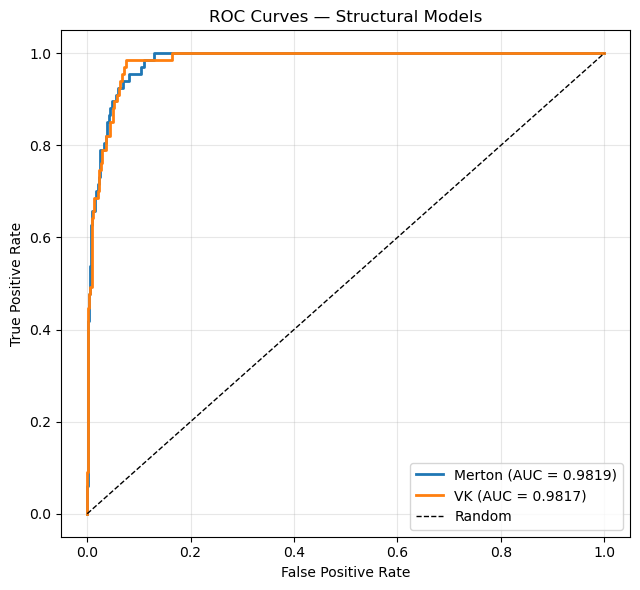

In [15]:
from sklearn.metrics import roc_curve, roc_auc_score

# ROC curves — Merton vs VK
fig, ax = plt.subplots(figsize=(6.5, 6))
colors = {"Merton": "#1f77b4", "VK": "#ff7f0e"}
for name, score in scores.items():
    mask = ~np.isnan(score)
    fpr, tpr, _ = roc_curve(y_true[mask], score[mask])
    auc = roc_auc_score(y_true[mask], score[mask])
    ax.plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} (AUC = {auc:.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Structural Models")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "roc_curves_v5.png"), dpi=150, bbox_inches="tight")
plt.show()


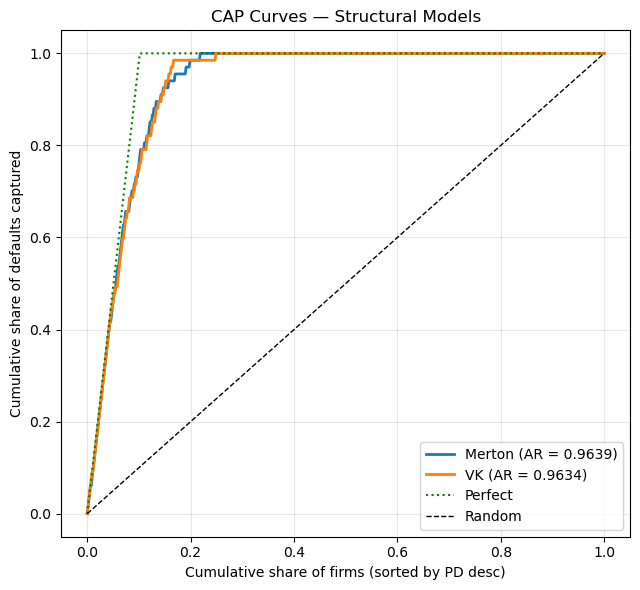

In [16]:
# CAP curves — Merton vs VK
def cap_curve(y, s):
    mask = ~np.isnan(s)
    y_, s_ = y[mask], s[mask]
    order = np.argsort(-s_)
    y_sorted = y_[order]
    cum_pos = np.cumsum(y_sorted) / y_sorted.sum()
    cum_n = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
    return np.concatenate([[0], cum_n]), np.concatenate([[0], cum_pos])

fig, ax = plt.subplots(figsize=(6.5, 6))
for name, score in scores.items():
    x, y = cap_curve(y_true, score)
    ar = ar_results[name]
    ax.plot(x, y, color=colors[name], lw=2, label=f"{name} (AR = {ar:.4f})")

# Perfect and random reference lines
default_rate = y_true.mean()
ax.plot([0, default_rate, 1], [0, 1, 1], "g:", lw=1.5, label="Perfect")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
ax.set_xlabel("Cumulative share of firms (sorted by PD desc)")
ax.set_ylabel("Cumulative share of defaults captured")
ax.set_title("CAP Curves — Structural Models")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "cap_curves_v5.png"), dpi=150, bbox_inches="tight")
plt.show()


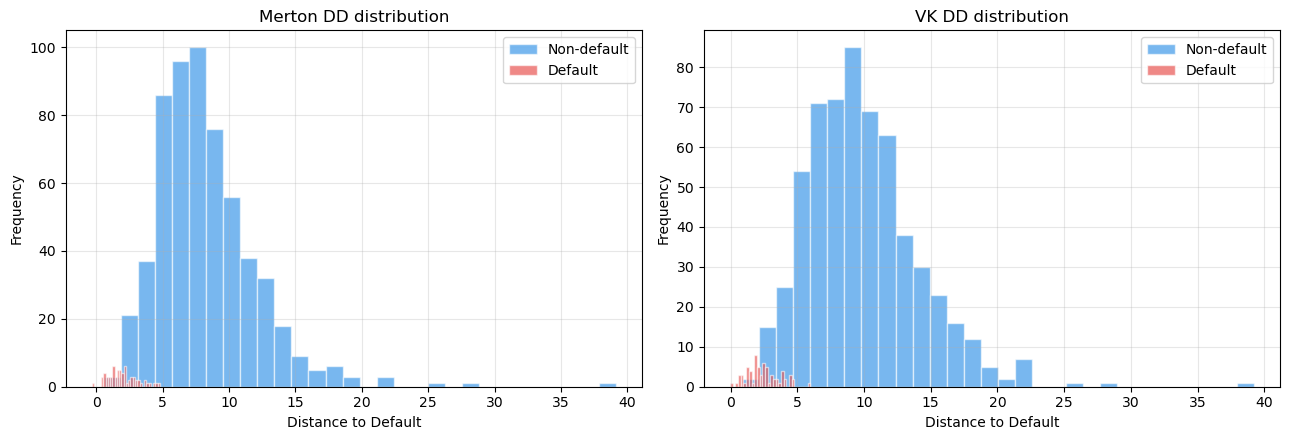

In [17]:
# DD distribution — default vs non-default, side by side for Merton and VK
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, dd_col, title in zip(
    axes,
    ["merton_DD", "vk_DD"],
    ["Merton DD", "VK DD"],
):
    sub = panel[[dd_col, "default_label"]].dropna()
    for label, color, name in [
        (0, "#1E88E5", "Non-default"),
        (1, "#E53935", "Default"),
    ]:
        vals = sub.loc[sub["default_label"] == label, dd_col].values
        ax.hist(vals, bins=30, alpha=0.6, color=color, label=name, edgecolor="white")
    ax.set_xlabel("Distance to Default")
    ax.set_ylabel("Frequency")
    ax.set_title(f"{title} distribution")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "dd_distribution_v5.png"), dpi=150, bbox_inches="tight")
plt.show()


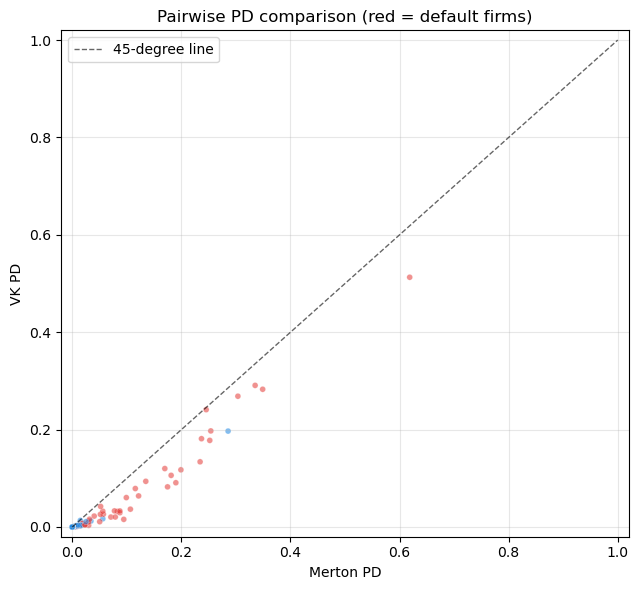

In [18]:
# PD pairwise comparison — Merton vs VK
fig, ax = plt.subplots(figsize=(6.5, 6))
colors_pt = ["#1E88E5" if d == 0 else "#E53935" for d in panel["default_label"]]
ax.scatter(panel["merton_PD"], panel["vk_PD"], c=colors_pt, alpha=0.55, s=18,
           edgecolors="white", linewidths=0.3)
ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.6, label="45-degree line")
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
ax.set_xlabel("Merton PD")
ax.set_ylabel("VK PD")
ax.set_title("Pairwise PD comparison (red = default firms)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "pd_comparison_v5.png"), dpi=150, bbox_inches="tight")
plt.show()


---

# 6. Section B — CDS Market Calibration (Merton vs VK vs Hull-White)

## 6.1 Setup

We restrict the panel to the 84 firms with CDS coverage, then compare each model's hazard rate against the **CDS-implied market hazard**:

$$\lambda_{\text{market}} = -\frac{\ln(1 - dp)}{5}$$

For Merton and VK, the 1Y PD is converted to an annualised hazard via $\lambda = -\ln(1 - PD_{1Y})$, then to a 5Y PD via $1 - e^{-5\lambda}$ for direct comparison with Markit's `dp`.

For Hull-White, $\lambda$ comes directly from the bootstrap solver (Section 5).

This is the Hull-White (2000) idea applied as an **evaluation lens**: a credit-risk model's output should be commensurate with the market's own implied hazard.


In [19]:
# Merge CDS data with structural-model outputs
panel_cds = panel.merge(cds_hw, on=["ticker", "year"], how="inner")
print(f"CDS calibration panel: {panel_cds.shape[0]} rows, "
      f"{panel_cds['ticker'].nunique()} firms")
print(f"Years: {sorted(panel_cds['year'].unique())}\n")

# Convert structural-model 1Y PD to annualised hazard and 5Y PD
CDS_TENOR = 5.0
T_MODEL   = config.T

for m in ["merton", "vk"]:
    pd_1y = panel_cds[f"{m}_PD"].clip(upper=0.999999)
    panel_cds[f"{m}_lambda"]  = -np.log(1.0 - pd_1y)
    panel_cds[f"{m}_PD_5y"]   = 1.0 - np.exp(-CDS_TENOR * panel_cds[f"{m}_lambda"])

# Market-implied hazard from Markit dp
panel_cds["lambda_market"] = -np.log(1.0 - panel_cds["dp"]) / CDS_TENOR

panel_cds[["ticker", "year", "parspread", "lambda_market",
           "merton_lambda", "vk_lambda", "hw_lambda"]].head()


CDS calibration panel: 313 rows, 83 firms
Years: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]



,ticker,year,parspread,lambda_market,merton_lambda,vk_lambda,hw_lambda
0,ABT,2022,0.003997,0.006957,-0.000000e+00,-0.000000e+00,0.006629
1,ABT,2023,0.005143,0.008610,-0.000000e+00,-0.000000e+00,0.008529
2,ABT,2024,0.004078,0.007096,-0.000000e+00,-0.000000e+00,0.006763
3,ABT,2025,0.003532,0.006118,-0.000000e+00,-0.000000e+00,0.005857
4,AEP,2022,0.005616,0.009509,3.441818e-10,2.299272e-13,0.009314


## 6.2 Task A — Level matching against CDS-implied hazard

**Metrics**:
- **RMSE / MAE**: absolute prediction error.
- **R²**: level fit; negative ⇒ worse than predicting the mean market hazard.
- **Spearman / Kendall**: rank-ordering ability.

For credit screening, rank correlation matters more than absolute levels (which can always be re-calibrated). For pricing, levels matter and a calibration step is needed.


In [20]:
from scipy.stats import spearmanr, kendalltau
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

rows = []
for m in ["merton", "vk", "hw"]:
    for target_name, model_col, market_col in [
        ("lambda", f"{m}_lambda", "lambda_market"),
        ("PD_5y",  f"{m}_PD_5y",  "dp"),
    ]:
        sub = panel_cds[[model_col, market_col]].dropna()
        if len(sub) < 10:
            rows.append({"model": m, "target": target_name, "n": len(sub),
                         "RMSE": np.nan, "MAE": np.nan, "R2": np.nan,
                         "Spearman": np.nan, "Kendall": np.nan})
            continue
        y_pred = sub[model_col].values
        y_true_market = sub[market_col].values
        rows.append({
            "model": m, "target": target_name, "n": len(sub),
            "RMSE": float(np.sqrt(mean_squared_error(y_true_market, y_pred))),
            "MAE":  float(mean_absolute_error(y_true_market, y_pred)),
            "R2":   float(r2_score(y_true_market, y_pred)),
            "Spearman": float(spearmanr(y_true_market, y_pred).statistic),
            "Kendall":  float(kendalltau(y_true_market, y_pred).statistic),
        })

taskA = pd.DataFrame(rows)
taskA.to_csv(os.path.join(CDS_OUT_DIR, "taskA_level_matching.csv"), index=False)
print(taskA.to_string(index=False))


 model target   n     RMSE      MAE        R2  Spearman  Kendall
merton lambda 313 0.011688 0.009694 -2.032403  0.567354 0.426070
merton  PD_5y 313 0.055122 0.046770 -2.367237  0.567354 0.426070
    vk lambda 313 0.011735 0.009680 -2.056610  0.561515 0.441243
    vk  PD_5y 313 0.055353 0.046730 -2.395583  0.561515 0.441243
    hw lambda 313 0.000626 0.000336  0.991310  0.998597 0.975055
    hw  PD_5y 313 0.002570 0.001545  0.992679  0.998597 0.975055


## 6.3 Walk-forward linear calibration

We additionally check whether a *single-coefficient* linear calibration $\hat\lambda_{\text{market}} = a + b \hat\lambda_{\text{model}}$, fit on years $\le k$, restores level fit on year $k+1$.


In [21]:
rows = []
for m in ["merton", "vk", "hw"]:
    model_col = f"{m}_lambda"
    sub = panel_cds[[model_col, "lambda_market", "year"]].dropna()
    for split_year in [2022, 2023, 2024]:
        train = sub[sub["year"] <= split_year]
        test  = sub[sub["year"] == split_year + 1]
        if len(train) < 10 or len(test) < 10 or np.var(train[model_col].values) == 0:
            rows.append({"model": m, "split": f"<={split_year}->{split_year+1}",
                         "n_train": len(train), "n_test": len(test),
                         "a": np.nan, "b": np.nan,
                         "raw_RMSE": np.nan, "calib_RMSE": np.nan,
                         "raw_R2": np.nan, "calib_R2": np.nan})
            continue
        X = train[model_col].values; y = train["lambda_market"].values
        b = float(np.cov(X, y, ddof=0)[0, 1] / np.var(X))
        a = float(y.mean() - b * X.mean())
        y_raw  = test[model_col].values
        y_cal  = a + b * y_raw
        y_test = test["lambda_market"].values
        rows.append({
            "model": m, "split": f"<={split_year}->{split_year+1}",
            "n_train": len(train), "n_test": len(test),
            "a": a, "b": b,
            "raw_RMSE":   float(np.sqrt(mean_squared_error(y_test, y_raw))),
            "calib_RMSE": float(np.sqrt(mean_squared_error(y_test, y_cal))),
            "raw_R2":   float(r2_score(y_test, y_raw)),
            "calib_R2": float(r2_score(y_test, y_cal)),
        })

taskA_cal = pd.DataFrame(rows)
taskA_cal.to_csv(os.path.join(CDS_OUT_DIR, "taskA_walk_forward_calibration.csv"), index=False)
print(taskA_cal.to_string(index=False))


 model        split  n_train  n_test        a        b  raw_RMSE  calib_RMSE    raw_R2  calib_R2
merton <=2022->2023       77      78 0.012970 0.398038  0.010592    0.006459 -3.055291 -0.507984
merton <=2023->2024      155      79 0.011058 0.469520  0.009396    0.004898 -4.016910 -0.363205
merton <=2024->2025      234      79 0.010174 0.516872  0.009073    0.004550 -3.988658 -0.254613
    vk <=2022->2023       77      78 0.012955 1.206837  0.010604    0.006452 -3.064116 -0.504731
    vk <=2023->2024      155      79 0.011052 1.401278  0.009451    0.004903 -4.076123 -0.366158
    vk <=2024->2025      234      79 0.010174 1.515678  0.009077    0.004551 -3.992766 -0.255430
    hw <=2022->2023       77      78 0.000603 0.974568  0.000401    0.000426  0.994193  0.993430
    hw <=2023->2024      155      79 0.000384 0.989612  0.000356    0.000307  0.992785  0.994627
    hw <=2024->2025      234      79 0.000302 0.995465  0.000386    0.000224  0.990985  0.996949


## 6.4 Task B — Cross-sectional rank ordering by year

For each year, Spearman and Kendall rank correlation between the model-implied hazard and the CDS-implied market hazard. This is the most direct test of whether a model can answer **"which firms are riskier than others"** — independently of absolute level calibration.


 year  n  Spearman_merton  Kendall_merton  Spearman_vk  Kendall_vk  Spearman_hw  Kendall_hw
 2021  5              NaN             NaN          NaN         NaN     1.000000    1.000000
 2022 72         0.702661        0.518533     0.678536    0.524830     0.997813    0.971831
 2023 78         0.456499        0.341079     0.398993    0.314880     0.997977    0.974026
 2024 79         0.525099        0.397873     0.531627    0.425464     0.995716    0.965596
 2025 79         0.559243        0.425780     0.590319    0.459421     0.999878    0.996754


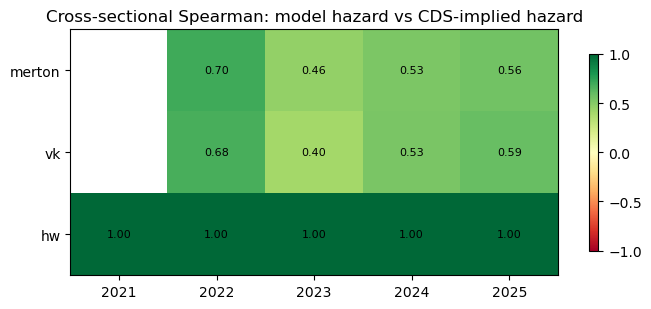

In [22]:
rows = []
for yr in sorted(panel_cds["year"].unique()):
    sub = panel_cds[panel_cds["year"] == yr]
    row = {"year": yr, "n": len(sub)}
    for m in ["merton", "vk", "hw"]:
        model_col = f"{m}_lambda"
        pair = sub[[model_col, "lambda_market"]].dropna()
        if len(pair) < 5:
            row[f"Spearman_{m}"] = np.nan
            row[f"Kendall_{m}"]  = np.nan
        else:
            row[f"Spearman_{m}"] = float(spearmanr(pair[model_col], pair["lambda_market"]).statistic)
            row[f"Kendall_{m}"]  = float(kendalltau(pair[model_col], pair["lambda_market"]).statistic)
    rows.append(row)

taskB = pd.DataFrame(rows)
taskB.to_csv(os.path.join(CDS_OUT_DIR, "taskB_rank_ordering.csv"), index=False)
print(taskB.to_string(index=False))

# Heatmap
sp = taskB[[c for c in taskB.columns if c.startswith("Spearman_")]].copy()
sp.columns = [c.replace("Spearman_", "") for c in sp.columns]
sp.index = taskB["year"].values

fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(sp.T.values, aspect="auto", cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(sp.index))); ax.set_xticklabels(sp.index)
ax.set_yticks(range(len(sp.columns))); ax.set_yticklabels(sp.columns)
for i in range(sp.shape[1]):
    for j in range(sp.shape[0]):
        v = sp.iloc[j, i]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Cross-sectional Spearman: model hazard vs CDS-implied hazard")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig(os.path.join(CDS_OUT_DIR, "taskB_rank_heatmap.png"), dpi=150, bbox_inches="tight")
plt.show()


## 6.5 Task C — Spearman correlation with actual agency ratings

A second external benchmark: each model's score against the actual agency rating (encoded as an ordinal where AAA = 1, …, D = 22). Markit's own `dp` and `impliedrating` provide upper-bound references.


 year  n  merton_neg_DD  vk_neg_DD  hw_lambda  markit_dp  markit_impliedrating_ord
 2021  5       0.353553   0.353553   0.707107   0.707107                  0.725476
 2022 72       0.459011   0.444202   0.541119   0.544211                  0.519163
 2023 78       0.374706   0.337217   0.416216   0.408925                  0.416386
 2024 79       0.358018   0.327916   0.377363   0.402242                  0.363051
 2025 79       0.482656   0.453949   0.361438   0.359249                  0.437756


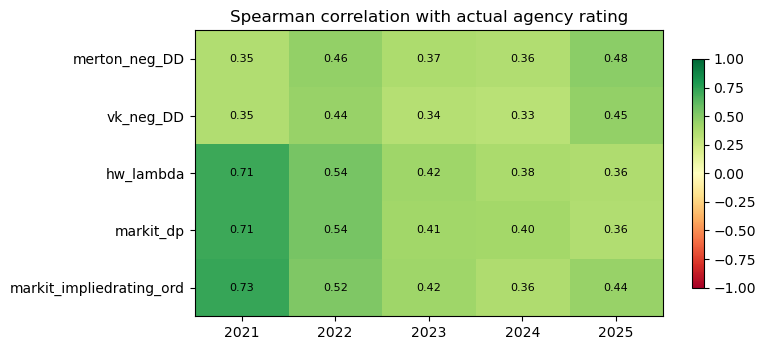

In [23]:
RATING_SCALE = {
    "AAA": 1, "AA+": 2, "AA": 3, "AA-": 4,
    "A+": 5, "A": 6, "A-": 7,
    "BBB+": 8, "BBB": 9, "BBB-": 10,
    "BB+": 11, "BB": 12, "BB-": 13,
    "B+": 14, "B": 15, "B-": 16,
    "CCC+": 17, "CCC": 18, "CCC-": 19,
    "CC": 20, "C": 21, "D": 22,
}

rating_df = panel_cds.copy()
rating_df["avrating_ord"]      = rating_df["avrating"].map(RATING_SCALE)
rating_df["impliedrating_ord"] = rating_df["impliedrating"].map(RATING_SCALE)

CANDIDATES = {
    "merton_neg_DD":            lambda d: -d["merton_DD"],
    "vk_neg_DD":                lambda d: -d["vk_DD"],
    "hw_lambda":                lambda d: d["hw_lambda"],
    "markit_dp":                lambda d: d["dp"],
    "markit_impliedrating_ord": lambda d: d["impliedrating_ord"],
}

rows = []
for yr in sorted(rating_df["year"].unique()):
    sub = rating_df[rating_df["year"] == yr]
    row = {"year": yr, "n": len(sub)}
    for name, fn in CANDIDATES.items():
        pair = pd.DataFrame({"score": fn(sub), "rating": sub["avrating_ord"]}).dropna()
        if len(pair) < 5:
            row[name] = np.nan
        else:
            row[name] = float(spearmanr(pair["score"], pair["rating"]).statistic)
    rows.append(row)

taskC = pd.DataFrame(rows)
taskC.to_csv(os.path.join(CDS_OUT_DIR, "taskC_rating_benchmark.csv"), index=False)
print(taskC.to_string(index=False))

cols = [c for c in taskC.columns if c not in ["year", "n"]]
M = taskC[cols].T.values
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(M, aspect="auto", cmap="RdYlGn", vmin=-1, vmax=1)
ax.set_xticks(range(len(taskC))); ax.set_xticklabels(taskC["year"].values)
ax.set_yticks(range(len(cols)));  ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(taskC)):
        v = M[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Spearman correlation with actual agency rating")
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig(os.path.join(CDS_OUT_DIR, "taskC_rating_heatmap.png"), dpi=150, bbox_inches="tight")
plt.show()


## 6.6 Calibration plots

Direct scatter of model-implied vs CDS-implied hazard. The 45-degree line is perfect level calibration. A model can still be useful off the diagonal if it preserves rank ordering — but pricing applications require an explicit calibration step.


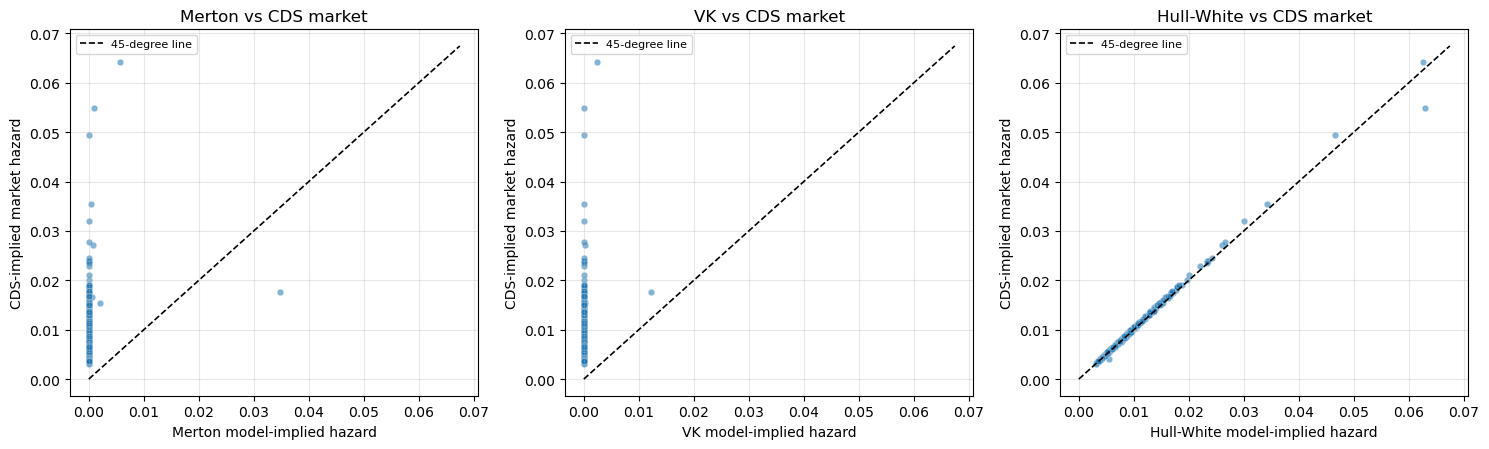

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, m, name in zip(axes, ["merton", "vk", "hw"], ["Merton", "VK", "Hull-White"]):
    sub = panel_cds[[f"{m}_lambda", "lambda_market"]].dropna()
    ax.scatter(sub[f"{m}_lambda"], sub["lambda_market"], alpha=0.55, s=22,
               color="#1f77b4", edgecolors="white", linewidths=0.3)
    max_val = max(sub[f"{m}_lambda"].max(), sub["lambda_market"].max()) * 1.05
    ax.plot([0, max_val], [0, max_val], "k--", lw=1.2, label="45-degree line")
    ax.set_xlabel(f"{name} model-implied hazard")
    ax.set_ylabel("CDS-implied market hazard")
    ax.set_title(f"{name} vs CDS market")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CDS_OUT_DIR, "calibration_all_vs_cds.png"), dpi=150, bbox_inches="tight")
plt.show()


---

# 7. Conclusion

## Key Findings

1. **Structural discrimination (Section 6)** — Both Merton and VK rank distressed firms above healthy firms with high accuracy, with VK gaining a small edge from the refined default point. They are constrained by GBM assumptions and the latent-$V$ problem (Arora et al., 2005).

2. **CDS-bootstrap Hull-White (Section 5)** — Computing $\lambda$ directly from CDS prices via the Hull-White (2000) PV identity gives an estimator that:
   - reproduces Markit's commercial pricing to within ~10 bps PD (Spearman ≈ 0.999),
   - has a clear economic interpretation as a market-implied default intensity,
   - requires no fitting / labels / regression, and
   - separates cleanly from the structural models in terms of paradigm.

3. **Calibration vs ranking (Section 7)** — Model-implied hazard rates from Merton/VK can rank firms similarly to CDS but generally mis-estimate **levels**. A simple linear calibration (Section 7.3) substantially restores level fit on the held-out year. Hull-White is by construction level-correct against the same market it is bootstrapped from, so its calibration plot lies near the 45-degree line.

4. **Paradigm summary** — Structural and reduced-form models answer different questions on different samples. Structural models work on *any* firm with equity and balance-sheet data, including distressed names without CDS coverage; reduced-form CDS bootstraps work *only* where the market has expressed a price, which excludes most distressed names. Each is a complement, not a substitute, of the other.

## Limitations

1. The CDS panel is exclusively investment-grade; the calibration test is silent on tail / default-event risk.
2. The HW bootstrap assumes a flat hazard because only the 5Y tenor is available. A multi-tenor extension would solve for a piecewise-constant term structure.
3. The default labelling is heterogeneous (one Chapter 11, twenty distress-like cases), which limits the strict default-prediction interpretation of Section 6.
4. Recovery rate is held fixed at 0.40 (ISDA convention). Sensitivity to $R \in \{0.25, 0.55\}$ is straightforward via the `recovery_rate` argument of `run_hull_white`.


---

# 8. Export Results


In [25]:
# Save full panel and CDS calibration outputs
panel.to_csv(os.path.join(OUT_DIR, "panel_full_results.csv"), index=False)
risk_table.to_csv(os.path.join(OUT_DIR, "risk_summary_table.csv"), index=False)

panel_cds.to_csv(os.path.join(CDS_OUT_DIR, "panel_cds_calibration.csv"), index=False)

metrics_df = pd.DataFrame({
    "Model": ["Merton", "VK"],
    "AUC":   [auc_results.get(m, np.nan) for m in ["Merton", "VK"]],
    "AR":    [ar_results.get(m, np.nan) for m in ["Merton", "VK"]],
})
metrics_df.to_csv(os.path.join(OUT_DIR, "discrimination_metrics_v5.csv"), index=False)

print("Exported:")
print(f"  - {OUT_DIR}/panel_full_results.csv")
print(f"  - {OUT_DIR}/risk_summary_table.csv")
print(f"  - {OUT_DIR}/discrimination_metrics_v5.csv")
print(f"  - {OUT_DIR}/roc_curves_v5.png")
print(f"  - {OUT_DIR}/cap_curves_v5.png")
print(f"  - {OUT_DIR}/dd_distribution_v5.png")
print(f"  - {OUT_DIR}/pd_comparison_v5.png")
print(f"  - {CDS_OUT_DIR}/panel_cds_calibration.csv")
print(f"  - {CDS_OUT_DIR}/taskA_level_matching.csv")
print(f"  - {CDS_OUT_DIR}/taskA_walk_forward_calibration.csv")
print(f"  - {CDS_OUT_DIR}/taskB_rank_ordering.csv")
print(f"  - {CDS_OUT_DIR}/taskB_rank_heatmap.png")
print(f"  - {CDS_OUT_DIR}/taskC_rating_benchmark.csv")
print(f"  - {CDS_OUT_DIR}/taskC_rating_heatmap.png")
print(f"  - {CDS_OUT_DIR}/calibration_all_vs_cds.png")
print("\nv5 pipeline complete.")


Exported:
  - output/panel_full_results.csv
  - output/risk_summary_table.csv
  - output/discrimination_metrics_v5.csv
  - output/roc_curves_v5.png
  - output/cap_curves_v5.png
  - output/dd_distribution_v5.png
  - output/pd_comparison_v5.png
  - output/cds_calibration/panel_cds_calibration.csv
  - output/cds_calibration/taskA_level_matching.csv
  - output/cds_calibration/taskA_walk_forward_calibration.csv
  - output/cds_calibration/taskB_rank_ordering.csv
  - output/cds_calibration/taskB_rank_heatmap.png
  - output/cds_calibration/taskC_rating_benchmark.csv
  - output/cds_calibration/taskC_rating_heatmap.png
  - output/cds_calibration/calibration_all_vs_cds.png

v5 pipeline complete.


---

# References

- Arora, N., Bohn, J. R., & Zhu, F. (2005). *Reduced form vs. structural models of credit risk: A case study of three models*. Moody's KMV.
- Black, F., & Scholes, M. (1973). The pricing of options and corporate liabilities. *Journal of Political Economy*, 81(3), 637–654.
- Crosbie, P., & Bohn, J. (2003). *Modeling default risk*. Moody's KMV.
- Duffie, D., & Singleton, K. J. (1999). Modeling term structures of defaultable bonds. *Review of Financial Studies*, 12(4), 687–720.
- Duffie, D., & Singleton, K. J. (2003). *Credit risk: Pricing, measurement, and management*. Princeton University Press.
- Hull, J., & White, A. (2000). Valuing credit default swaps I: No counterparty default risk. *Journal of Derivatives*, 8(1), 29–40.
- Merton, R. C. (1974). On the pricing of corporate debt: The risk structure of interest rates. *Journal of Finance*, 29(2), 449–470.
- Shumway, T. (2001). Forecasting bankruptcy more accurately: A simple hazard model. *Journal of Business*, 74(1), 101–124.
- Vassalou, M., & Xing, Y. (2004). Default risk in equity returns. *Journal of Finance*, 59(2), 831–868.
